# 06 — Brain-only 3D reconstruction from CT

This standalone notebook reconstructs **only the brain** and does not run the ten-organ Phase 6
uncertainty or locked-test workflow.

**Input contract:** one 3D CT NIfTI volume and one matching binary brain-mask NIfTI volume. The current
project checkpoint was trained for ten thoracic/abdominal organs and has no brain output, so this notebook
uses an existing brain mask; it does not claim CT-only brain prediction. For an unseen CT, first obtain a
brain mask from a separately trained/validated brain segmentation model.

The output is a patient-space brain surface exported as full-resolution PLY, STL, GLB, an interactive HTML
viewer, a PNG preview, and a JSON geometry report.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import plotly.graph_objects as go
import trimesh
from IPython.display import IFrame, Image, Markdown, display
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from skimage.measure import marching_cubes

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook with F:/csstdy as the working directory")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATASET_ROOT = Path(
    os.environ.get("TOTALSEG_DATASET_ROOT", PROJECT_ROOT / "Totalsegmentator_dataset_v201")
).resolve()

# Safe demonstration case from the validation split. Change CASE_ID to another labeled dataset case.
CASE_ID = "s0346"

# For custom data, set BOTH paths to matching 3D NIfTI files (.nii or .nii.gz).
# A brain mask is required because the current project checkpoint does not predict brain.
CT_PATH = None
BRAIN_MASK_PATH = None

# This brain mesh is small enough to render in full; no triangles are dropped.
MAX_INTERACTIVE_FACES = 150_000
MAX_PREVIEW_FACES = 150_000
SMOOTHING_ITERATIONS = 20
SMOOTHING_LAMBDA = 0.5
SMOOTHING_NU = 0.525
OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "brain_3d" / CASE_ID
BRAIN_COLOR = (224, 184, 168, 235)

## 1. Load and validate CT and brain mask

The volumes must be three-dimensional, share the same voxel grid and affine, contain finite CT values,
and contain a non-empty binary brain mask. Dataset files are read-only.

In [2]:
if (CT_PATH is None) != (BRAIN_MASK_PATH is None):
    raise ValueError("Set both CT_PATH and BRAIN_MASK_PATH, or leave both as None")

if CT_PATH is None:
    case_root = DATASET_ROOT / CASE_ID
    ct_path = case_root / "ct.nii.gz"
    brain_mask_path = case_root / "segmentations" / "brain.nii.gz"
    input_source = "TotalSegmentator reference mask (not a model prediction)"
else:
    ct_path = Path(CT_PATH).expanduser().resolve()
    brain_mask_path = Path(BRAIN_MASK_PATH).expanduser().resolve()
    input_source = "user-supplied brain mask (not generated by this notebook)"

if not ct_path.is_file():
    raise FileNotFoundError(f"CT not found: {ct_path}")
if not brain_mask_path.is_file():
    raise FileNotFoundError(f"Brain mask not found: {brain_mask_path}")

ct_image = nib.load(str(ct_path))
mask_image = nib.load(str(brain_mask_path))
ct = np.asarray(ct_image.dataobj, dtype=np.float32)
raw_mask = np.asanyarray(mask_image.dataobj)

if ct.ndim != 3 or raw_mask.ndim != 3:
    raise ValueError(f"Expected 3D volumes, got CT {ct.shape} and mask {raw_mask.shape}")
if ct.shape != raw_mask.shape:
    raise ValueError(f"CT/mask shape mismatch: {ct.shape} != {raw_mask.shape}")
if not np.allclose(ct_image.affine, mask_image.affine, rtol=0.0, atol=1e-4):
    raise ValueError("CT and brain-mask affines do not match")
if not np.isfinite(ct).all():
    raise ValueError("CT contains non-finite values")

mask_values = np.unique(raw_mask)
if not np.all(np.isin(mask_values, (0, 1))):
    raise ValueError(f"Brain mask must be binary; found {mask_values.tolist()}")
brain_mask = raw_mask.astype(bool)
if not brain_mask.any():
    raise ValueError("Brain mask is empty; choose a scan that includes the brain")

affine = np.asarray(mask_image.affine, dtype=np.float64)
spacing_mm = np.asarray(mask_image.header.get_zooms()[:3], dtype=np.float64)
brain_voxels = int(brain_mask.sum())
voxel_volume_mm3 = float(abs(np.linalg.det(affine[:3, :3])))
mask_volume_ml = brain_voxels * voxel_volume_mm3 / 1000.0

display(Markdown(
    f"**Case:** `{CASE_ID}`  \n"
    f"**Source:** {input_source}  \n"
    f"**Shape:** `{ct.shape}` voxels  \n"
    f"**Spacing:** `{spacing_mm.round(4).tolist()}` mm  \n"
    f"**Brain voxels:** `{brain_voxels:,}`  \n"
    f"**Mask-derived volume:** `{mask_volume_ml:,.2f} mL`"
))

**Case:** `s0346`  
**Source:** TotalSegmentator reference mask (not a model prediction)  
**Shape:** `(215, 215, 241)` voxels  
**Spacing:** `[1.5, 1.5, 1.5]` mm  
**Brain voxels:** `438,565`  
**Mask-derived volume:** `1,480.16 mL`

## 2. CT and mask quality-control overlay

The displayed axial, coronal, and sagittal slices pass through the brain mask's center of mass.

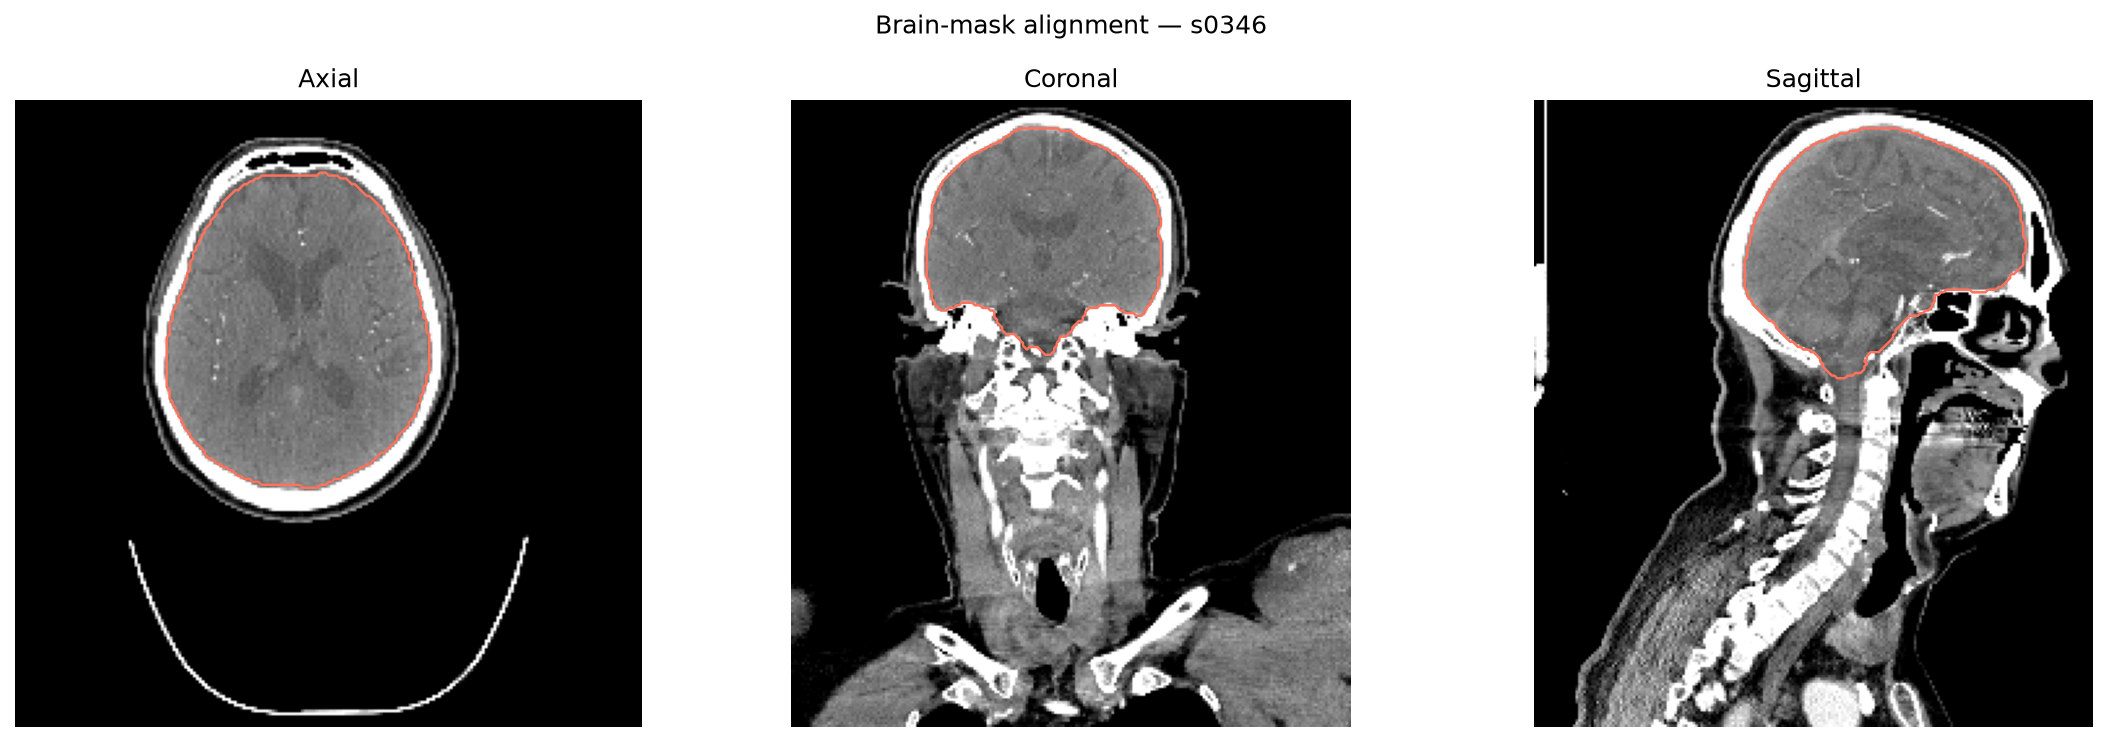

In [3]:
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
brain_coordinates = np.argwhere(brain_mask)
center = np.rint(brain_coordinates.mean(axis=0)).astype(int)

slices = [
    (ct[:, :, center[2]].T, brain_mask[:, :, center[2]].T, "Axial"),
    (ct[:, center[1], :].T, brain_mask[:, center[1], :].T, "Coronal"),
    (ct[center[0], :, :].T, brain_mask[center[0], :, :].T, "Sagittal"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=150)
for axis, (ct_slice, mask_slice, title) in zip(axes, slices):
    axis.imshow(ct_slice, cmap="gray", vmin=-100, vmax=200, origin="lower")
    axis.contour(mask_slice.astype(np.uint8), levels=[0.5], colors=["#ff725c"], linewidths=1.2)
    axis.set_title(title)
    axis.axis("off")
fig.suptitle(f"Brain-mask alignment — {CASE_ID}")
fig.tight_layout()
overlay_path = OUTPUT_ROOT / f"{CASE_ID}_brain_overlay.png"
fig.savefig(overlay_path, bbox_inches="tight")
plt.show()

## 3. Full-resolution brain surface reconstruction

Marching cubes extracts the binary-mask surface. Vertices are transformed by the NIfTI affine into RAS
patient-space millimetres. The PLY, STL, and GLB retain the full mesh; only the browser view is face-capped.

In [4]:
# Padding guarantees a closed level crossing even if a custom mask touches an image boundary.
padded_mask = np.pad(brain_mask.astype(np.uint8), 1, mode="constant")
voxel_vertices, faces, _normals, _values = marching_cubes(
    padded_mask, level=0.5, step_size=1, allow_degenerate=False
)
voxel_vertices -= 1.0
homogeneous = np.column_stack(
    (voxel_vertices, np.ones(voxel_vertices.shape[0], dtype=np.float64))
)
world_vertices = (homogeneous @ affine.T)[:, :3].astype(np.float32)
vertex_colors = np.tile(
    np.asarray(BRAIN_COLOR, dtype=np.uint8), (world_vertices.shape[0], 1)
)

brain_mesh = trimesh.Trimesh(
    vertices=world_vertices,
    faces=faces,
    vertex_colors=vertex_colors,
    process=True,
    validate=True,
)
brain_mesh.remove_unreferenced_vertices()

# Taubin smoothing removes voxel-grid terracing while limiting the shrinkage
# caused by ordinary Laplacian smoothing. Connectivity and watertightness remain intact.
trimesh.smoothing.filter_taubin(
    brain_mesh,
    lamb=SMOOTHING_LAMBDA,
    nu=SMOOTHING_NU,
    iterations=SMOOTHING_ITERATIONS,
)
brain_mesh.fix_normals(multibody=True)

ply_path = OUTPUT_ROOT / f"{CASE_ID}_brain.ply"
stl_path = OUTPUT_ROOT / f"{CASE_ID}_brain.stl"
glb_path = OUTPUT_ROOT / f"{CASE_ID}_brain.glb"
brain_mesh.export(ply_path)
brain_mesh.export(stl_path)
scene = trimesh.Scene()
scene.add_geometry(brain_mesh.copy(), node_name="brain", geom_name="brain")
glb_path.write_bytes(scene.export(file_type="glb"))

face_indices = np.arange(len(brain_mesh.faces))
if face_indices.size > MAX_INTERACTIVE_FACES:
    face_indices = np.linspace(
        0, face_indices.size - 1, MAX_INTERACTIVE_FACES, dtype=np.int64
    )
shown_faces = brain_mesh.faces[face_indices]
color_hex = "#%02x%02x%02x" % BRAIN_COLOR[:3]
interactive = go.Figure(
    data=[
        go.Mesh3d(
            x=brain_mesh.vertices[:, 0],
            y=brain_mesh.vertices[:, 1],
            z=brain_mesh.vertices[:, 2],
            i=shown_faces[:, 0],
            j=shown_faces[:, 1],
            k=shown_faces[:, 2],
            name="brain",
            color=color_hex,
            opacity=BRAIN_COLOR[3] / 255.0,
            flatshading=False,
            hovertemplate="brain<extra></extra>",
        )
    ]
)
interactive.update_layout(
    title=f"Brain-only 3D reconstruction — {CASE_ID}",
    template="plotly_dark",
    scene={
        "aspectmode": "data",
        "xaxis_title": "R–L (mm)",
        "yaxis_title": "A–P (mm)",
        "zaxis_title": "I–S (mm)",
        "camera": {"eye": {"x": 1.45, "y": 1.45, "z": 1.15}},
    },
    margin={"l": 0, "r": 0, "t": 50, "b": 0},
)
html_path = OUTPUT_ROOT / f"{CASE_ID}_brain.html"
interactive.write_html(html_path, include_plotlyjs=True, full_html=True)

preview_path = OUTPUT_ROOT / f"{CASE_ID}_brain_preview.png"
fig = plt.figure(figsize=(9, 9), dpi=160)
axis = fig.add_subplot(111, projection="3d")
preview_face_indices = np.arange(len(brain_mesh.faces))
if preview_face_indices.size > MAX_PREVIEW_FACES:
    preview_face_indices = np.linspace(
        0, preview_face_indices.size - 1, MAX_PREVIEW_FACES, dtype=np.int64
    )
preview_faces = brain_mesh.faces[preview_face_indices]
collection = Poly3DCollection(
    brain_mesh.vertices[preview_faces], linewidths=0, alpha=BRAIN_COLOR[3] / 255.0
)
collection.set_facecolor(np.asarray(BRAIN_COLOR[:3], dtype=float) / 255.0)
axis.add_collection3d(collection)
mins, maxs = brain_mesh.bounds
centers = (mins + maxs) / 2.0
radius = float(np.max(maxs - mins) / 2.0)
axis.set_xlim(centers[0] - radius, centers[0] + radius)
axis.set_ylim(centers[1] - radius, centers[1] + radius)
axis.set_zlim(centers[2] - radius, centers[2] + radius)
axis.set_xlabel("R–L (mm)")
axis.set_ylabel("A–P (mm)")
axis.set_zlabel("I–S (mm)")
axis.set_title(f"Brain-only 3D reconstruction — {CASE_ID}")
axis.view_init(elev=15, azim=-70)
fig.tight_layout()
fig.savefig(preview_path, bbox_inches="tight")
plt.close(fig)

report = {
    "schema_version": 1,
    "case_id": CASE_ID,
    "input_source": input_source,
    "ct_path": str(ct_path),
    "brain_mask_path": str(brain_mask_path),
    "coordinate_system": "NIfTI patient-space millimetres",
    "brain_voxels": brain_voxels,
    "mask_volume_ml": mask_volume_ml,
    "vertices": int(len(brain_mesh.vertices)),
    "faces": int(len(brain_mesh.faces)),
    "watertight": bool(brain_mesh.is_watertight),
    "surface_area_mm2": float(brain_mesh.area),
    "mesh_volume_ml_if_watertight": (
        float(abs(brain_mesh.volume) / 1000.0) if brain_mesh.is_watertight else None
    ),
    "full_resolution_exports": True,
    "surface_smoothing": {
        "method": "Taubin",
        "iterations": SMOOTHING_ITERATIONS,
        "lambda": SMOOTHING_LAMBDA,
        "nu": SMOOTHING_NU,
    },
    "interactive_html_face_cap": MAX_INTERACTIVE_FACES,
    "ply": ply_path.name,
    "stl": stl_path.name,
    "glb": glb_path.name,
    "interactive_html": html_path.name,
    "overlay_png": overlay_path.name,
    "preview_png": preview_path.name,
}
report_path = OUTPUT_ROOT / "brain_mesh_report.json"
report_path.write_text(json.dumps(report, indent=2, allow_nan=False) + "\n", encoding="utf-8")
report

{'schema_version': 1,
 'case_id': 's0346',
 'input_source': 'TotalSegmentator reference mask (not a model prediction)',
 'ct_path': 'F:\\csstdy\\Totalsegmentator_dataset_v201\\s0346\\ct.nii.gz',
 'brain_mask_path': 'F:\\csstdy\\Totalsegmentator_dataset_v201\\s0346\\segmentations\\brain.nii.gz',
 'coordinate_system': 'NIfTI patient-space millimetres',
 'brain_voxels': 438565,
 'mask_volume_ml': 1480.156875,
 'vertices': 46324,
 'faces': 92644,
 'watertight': True,
 'surface_area_mm2': 70665.06364852174,
 'mesh_volume_ml_if_watertight': 1479.9651276731806,
 'full_resolution_exports': True,
 'surface_smoothing': {'method': 'Taubin',
  'iterations': 20,
  'lambda': 0.5,
  'nu': 0.525},
 'interactive_html_face_cap': 150000,
 'ply': 's0346_brain.ply',
 'stl': 's0346_brain.stl',
 'glb': 's0346_brain.glb',
 'interactive_html': 's0346_brain.html',
 'overlay_png': 's0346_brain_overlay.png',
 'preview_png': 's0346_brain_preview.png'}

## 4. Brain-only outputs

- **Interactive viewer:** `outputs\brain_3d\s0346\s0346_brain.html`
- **Portable GLB:** `outputs\brain_3d\s0346\s0346_brain.glb`
- **Full-resolution PLY:** `outputs\brain_3d\s0346\s0346_brain.ply`
- **Full-resolution STL:** `outputs\brain_3d\s0346\s0346_brain.stl`
- **Geometry report:** `outputs\brain_3d\s0346\brain_mesh_report.json`

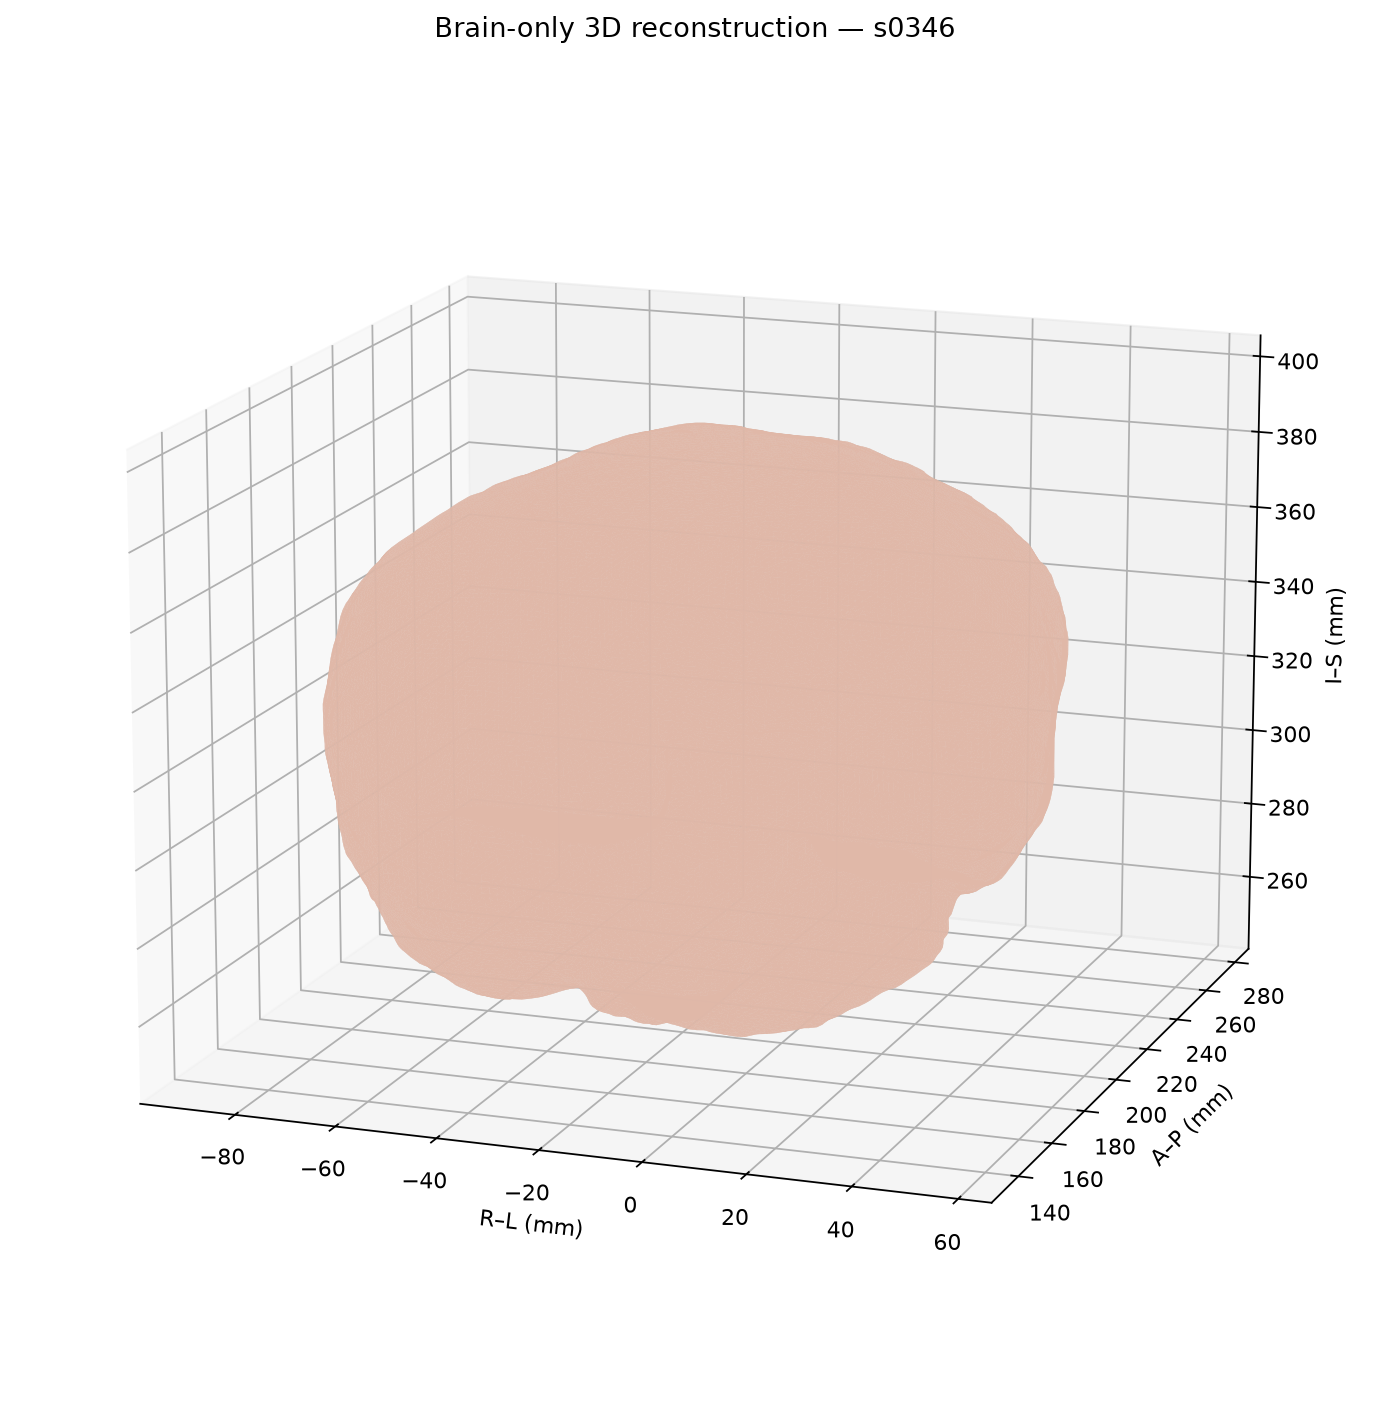

In [5]:
display(Markdown(
    f"- **Interactive viewer:** `{html_path.relative_to(PROJECT_ROOT)}`\n"
    f"- **Portable GLB:** `{glb_path.relative_to(PROJECT_ROOT)}`\n"
    f"- **Full-resolution PLY:** `{ply_path.relative_to(PROJECT_ROOT)}`\n"
    f"- **Full-resolution STL:** `{stl_path.relative_to(PROJECT_ROOT)}`\n"
    f"- **Geometry report:** `{report_path.relative_to(PROJECT_ROOT)}`"
))
display(Image(filename=str(preview_path)))
display(IFrame(src=html_path.as_uri(), width="100%", height=760))